# Поиск по документам: TF-IDF и SVD

На прошлом занятии сообщение получало название отдела. Теперь пользователю нужен конкретный документ: например, инструкция по продлению книги. Построим два варианта поиска по одной базе и посмотрим, когда изменение представления меняет порядок результатов.

В базе двенадцать документов. Вопросы хранятся отдельно; часть из них относится к сведениям, которых в документах нет.

In [1]:
from pathlib import Path
import os
import json
import re
import unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Находим корень раздачи независимо от места запуска Jupyter.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "data" / "requests.csv").exists())
DATA = ROOT / "data"
os.environ["HF_HUB_OFFLINE"] = "1"
os.environ["TRANSFORMERS_OFFLINE"] = "1"
os.environ["TOKENIZERS_PARALLELISM"] = "false"
np.random.seed(42)
plt.rcParams.update({"font.family": "DejaVu Sans", "figure.figsize": (8, 4)})


## Что будем искать

Откройте список документов и выберите тот, в котором ожидаете найти условия продления книги. Позже сравним это предположение с выдачей. Поле `relevant_doc` в таблице вопросов содержит эталонный документ; пустая строка означает, что ответа в базе нет. Эти метки используются при оценке, а не при построении индекса.

In [2]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import normalize
from sklearn.metrics.pairwise import cosine_similarity

docs = pd.read_csv(DATA / "knowledge.csv", keep_default_na=False)
queries = pd.read_csv(DATA / "retrieval_queries.csv", keep_default_na=False)
content = docs["title"] + ". " + docs["text"]
doc_ids = docs["doc_id"].to_numpy()
assert docs["doc_id"].is_unique
assert not {"relevant_doc", "reference_answer"} & set(docs.columns)
print("Документов:", len(docs), "Вопросов:", len(queries))
display(docs[["doc_id", "title"]])

Документов: 12 Вопросов: 30


,doc_id,title
0,D01,Восстановление доступа
1,D02,Техническая поддержка
2,D03,Продление книг
3,D04,Читальный зал
4,D05,Заселение
5,D06,Ремонт в комнате
6,D07,Пересдача
7,D08,Исправление ведомости
8,D09,Документы абитуриента
9,D10,Консультации поступающим


### Один расчёт перед функцией

Пусть запрос представлен вектором (1;0), а документ — (1;1). Их скалярное произведение равно 1, а произведение длин равно √2. Следующая ячейка воспроизводит расчёт. Увеличьте второй вектор в десять раз и сначала предскажите результат.

In [3]:
demo_query = np.array([1., 0.])
demo_document = np.array([1., 1.])
print(np.dot(demo_query, demo_document) / (np.linalg.norm(demo_query) * np.linalg.norm(demo_document)))

0.7071067811865475


## 1. Сходство направлений

Напишите `cosine_safe(a, b)` для одномерных векторов одинаковой размерности. Используйте скалярное произведение и евклидовы нормы. Если размерности не совпадают или одна из норм равна нулю, вызывайте `ValueError`.

Сравните (1;0) с (1;1), (0;1), (10;10) и (−1;0). Объясните, почему положительный масштаб не влияет на косинус, а отрицательный меняет его знак. Можно ли прочитать число 0,7071 как вероятность правильного ответа?

In [4]:
def cosine_safe(a, b):
    a, b = np.asarray(a, dtype=float), np.asarray(b, dtype=float)
    if a.shape != b.shape or a.ndim != 1:
        raise ValueError("Нужны векторы одинаковой размерности")
    denominator = np.linalg.norm(a) * np.linalg.norm(b)
    if denominator == 0:
        raise ValueError("Косинус нулевого вектора не определён")
    return float(np.dot(a, b) / denominator)

for b in [(1, 1), (0, 1), (10, 10), (-1, 0)]:
    print(b, cosine_safe((1, 0), b))

(1, 1) 0.7071067811865475
(0, 1) 0.0
(10, 10) 0.7071067811865475
(-1, 0) -1.0


In [5]:
assert np.isclose(cosine_safe([1, 0], [1, 1]), 1 / np.sqrt(2))
assert np.isclose(cosine_safe([1, 0], [10, 10]), cosine_safe([1, 0], [1, 1]))
try:
    cosine_safe([0, 0], [1, 0])
except ValueError:
    pass
else:
    raise AssertionError("Нужна явная обработка нулевого вектора")

Получаются примерно 0,7071; 0; 0,7071; −1. Два первых ненулевых направления задают угол 45°, увеличение длины его не меняет. Косинус здесь описывает геометрию выбранных координат; вероятность правильности ответа из этого расчёта не следует.

## 2. Два представления одной базы

Обучите `vectorizer = TfidfVectorizer(ngram_range=(1, 2), norm="l2")` на `content` и сохраните матрицу в `X_docs`. Затем обучите `svd = TruncatedSVD(n_components=6, random_state=42)` на этой матрице. Нормируйте полученные строки через `normalize` и сохраните их в `Z_docs`.

Сравните формы матриц и количество ненулевых элементов. Объясните, что теперь означает строка и что изменилось в её координатах. Почему для индекса можно использовать все известные документы, но нельзя добавлять в обучение проверочные вопросы с ответами?

In [6]:
vectorizer = TfidfVectorizer(ngram_range=(1, 2), norm="l2")
X_docs = vectorizer.fit_transform(content)
svd = TruncatedSVD(n_components=6, random_state=42)
Z_docs = normalize(svd.fit_transform(X_docs))
print("TF-IDF:", X_docs.shape, "SVD:", Z_docs.shape)
print("Ненулевых элементов TF-IDF:", X_docs.nnz)
print("Нормы SVD:", np.linalg.norm(Z_docs, axis=1).round(6))

TF-IDF: (12, 670) SVD: (12, 6)
Ненулевых элементов TF-IDF: 816
Нормы SVD: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [7]:
assert X_docs.shape[0] == len(docs)
assert Z_docs.shape == (len(docs), 6)
assert np.allclose(np.linalg.norm(Z_docs, axis=1), 1)
assert svd.components_.shape[1] == len(vectorizer.vocabulary_)

TF-IDF даёт матрицу 12×670 с 816 ненулевыми элементами; SVD — 12×6. В обоих случаях строка относится к тому же документу. Координаты SVD являются сочетаниями исходных признаков. Документы доступны системе заранее; новые вопросы проверяют поиск в этой коллекции.

## 3. От запроса к выдаче

Закончите `search(query, method="tfidf", k=3)`. Запрос должен проходить через уже обученные `vectorizer` и, для метода `svd`, `svd` с последующей нормировкой. Сравните его с соответствующей матрицей документов.

Верните DataFrame с колонками `doc_id`, `title`, `score`: сначала большая неокруглённая оценка, при равенстве — меньший `doc_id`. Для нулевого вектора запроса верните пустую таблицу с теми же колонками. Проверьте оба метода на вопросе «Как продлить книгу?», пустой строке и строке «щщщщщщщ».

Почему новое `fit` на одном запросе испортило бы сравнение, даже если удалось получить массив нужного размера?

In [8]:
def search(query, method="tfidf", k=3):
    if method not in {"tfidf", "svd"} or not 1 <= k <= len(docs):
        raise ValueError("Проверьте метод и k")
    empty = pd.DataFrame(columns=["doc_id", "title", "score"])
    q = vectorizer.transform([query])
    if q.nnz == 0:
        return empty
    if method == "tfidf":
        scores = cosine_similarity(q, X_docs).ravel()
    else:
        z = svd.transform(q)
        if np.linalg.norm(z) < 1e-12:
            return empty
        scores = (normalize(z) @ Z_docs.T).ravel()
    result = docs[["doc_id", "title"]].assign(score=scores)
    return result.sort_values(["score", "doc_id"], ascending=[False, True], kind="stable").head(k).reset_index(drop=True)

for method in ["tfidf", "svd"]:
    print(method)
    display(search("Можно оставить учебник ещё на неделю?", method))
    display(search("щщщщщщщ", method))

tfidf


,doc_id,title,score
0,D03,Продление книг,0.159405
1,D01,Восстановление доступа,0.117213
2,D07,Пересдача,0.039721


,doc_id,title,score


svd


,doc_id,title,score
0,D03,Продление книг,0.852191
1,D01,Восстановление доступа,0.819824
2,D02,Техническая поддержка,0.354820


,doc_id,title,score


In [9]:
for method in ["tfidf", "svd"]:
    r = search("Как продлить книгу?", method, 3)
    assert list(r.columns) == ["doc_id", "title", "score"]
    assert len(r) <= 3 and r["doc_id"].is_unique
    assert r["score"].is_monotonic_decreasing
    assert search("", method).empty
    assert search("щщщщщщщ", method).empty

Одни и те же координаты должны иметь одинаковый смысл у запроса и документов. У пустой строки и неизвестного набора букв TF-IDF нулевой, поэтому косинус не определён. Частично знакомый запрос может оказаться ненулевым и всё же не содержать достаточно информации для полезной выдачи.

## 4. Считаем попадания и ранги

Реализуйте `evaluate(part, method)`. В среднее включайте только вопросы с непустым `relevant_doc`. Возвращайте словарь с ключами `recall_at_1`, `recall_at_3`, `mrr_at_3`, `n_answerable`. Если эталон отсутствует в первых трёх результатах, его вклад в MRR@3 равен нулю.

Соберите `results_table` с колонками `split`, `method` и четырьмя показателями. Сравните заранее выбранные TF-IDF и SVD(6) на validation, затем на test. После просмотра теста оставьте настройки неизменными.

Проверьте формулы на четырёх рангах из лекции: 1, 3, отсутствие в top-3 и 2. Чем отличаются Recall@3 и MRR@3 на этом примере?

,split,method,recall_at_1,recall_at_3,mrr_at_3,n_answerable
0,validation,tfidf,0.750,0.8750,0.791667,8
1,validation,svd,0.875,0.8750,0.875000,8
2,test,tfidf,0.875,0.9375,0.906250,16
3,test,svd,0.875,1.0000,0.916667,16


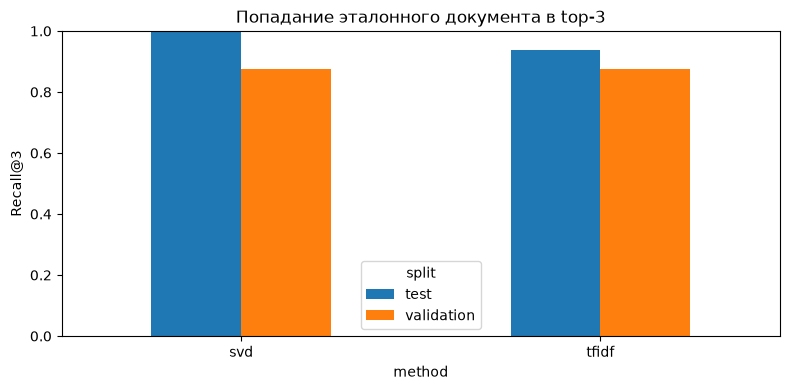

Различающиеся выдачи:
{'query_id': 'Q01', 'query': 'Как долго действует ссылка для смены пароля?', 'relevant_doc': 'D01', 'tfidf': ['D01', 'D04', 'D11'], 'svd': ['D01', 'D02', 'D03']}
{'query_id': 'Q02', 'query': 'Что проверить, если письмо восстановления не пришло?', 'relevant_doc': 'D01', 'tfidf': ['D01', 'D03', 'D08'], 'svd': ['D01', 'D03', 'D02']}
{'query_id': 'Q03', 'query': 'Во сколько заканчивает работу служба ИТ?', 'relevant_doc': 'D02', 'tfidf': ['D02', 'D01', 'D03'], 'svd': ['D02', 'D04', 'D01']}
{'query_id': 'Q04', 'query': 'Какие сведения нужны при технической ошибке?', 'relevant_doc': 'D02', 'tfidf': ['D05', 'D01', 'D02'], 'svd': ['D02', 'D01', 'D04']}


In [10]:
def evaluate(part, method):
    answerable = part.loc[part["relevant_doc"].ne("")]
    if answerable.empty:
        raise ValueError("Нет ответимых вопросов для Recall")
    r1, r3, rr = [], [], []
    for row in answerable.itertuples():
        ranking = search(row.query, method, 3)["doc_id"].tolist()
        found = row.relevant_doc in ranking
        r1.append(bool(ranking) and ranking[0] == row.relevant_doc)
        r3.append(found)
        rr.append(1 / (ranking.index(row.relevant_doc) + 1) if found else 0)
    return {"recall_at_1": float(np.mean(r1)), "recall_at_3": float(np.mean(r3)),
            "mrr_at_3": float(np.mean(rr)), "n_answerable": len(answerable)}

rows = []
for split in ["validation", "test"]:
    for method in ["tfidf", "svd"]:
        rows.append({"split": split, "method": method,
                     **evaluate(queries[queries["split"].eq(split)], method)})
results_table = pd.DataFrame(rows)
display(results_table)
results_table.pivot(index="method", columns="split", values="recall_at_3").plot.bar(ylim=(0, 1), rot=0)
plt.ylabel("Recall@3"); plt.title("Попадание эталонного документа в top-3"); plt.tight_layout(); plt.show()
diagnostics = []
for row in queries[queries["relevant_doc"].ne("")].itertuples():
    a = search(row.query, "tfidf", 3)["doc_id"].tolist()
    b = search(row.query, "svd", 3)["doc_id"].tolist()
    if a != b:
        diagnostics.append({"query_id": row.query_id, "query": row.query,
                            "relevant_doc": row.relevant_doc, "tfidf": a, "svd": b})
print("Различающиеся выдачи:")
for row in diagnostics[:4]:
    print(row)

In [11]:
assert (results_table["recall_at_3"] >= results_table["recall_at_1"] - 1e-12).all()
assert results_table["mrr_at_3"].between(0, 1).all()
assert set(results_table["n_answerable"]) == {8, 16}
# Четыре ранга из лекции: 1, 3, отсутствие и 2.
assert np.isclose(np.mean([1, 1/3, 0, 1/2]), 11/24)


В ручном примере Recall@1=0,25, Recall@3=0,75, MRR@3≈0,4583. В таблице эксперимента знаменатели равны 8 и 16. Вопросы без ответа не входят в эти средние: для них нужна отдельная проверка достаточности источника.

## Читаем различия выдач

Следующая ячейка собирает вопросы, для которых порядок документов отличается, и показывает оценки. Выберите два таких вопроса для разбора. Если документ попал в выдачу с нулевой оценкой, проверьте роль сортировки при равенстве.

После таблицы появятся вопросы без ответа в базе. Поиск всё равно может вернуть близкий документ. Прочитайте его и найдите, какого именно факта не хватает. Особенно полезен вопрос о сумме стипендии.

In [12]:
differences = []
for row in queries[queries["relevant_doc"].ne("")].itertuples():
    first = search(row.query, "tfidf", 3)
    second = search(row.query, "svd", 3)
    if first["doc_id"].tolist() != second["doc_id"].tolist():
        differences.append({"query_id": row.query_id, "query": row.query,
                            "relevant_doc": row.relevant_doc,
                            "tfidf": list(zip(first["doc_id"], first["score"].round(6))),
                            "svd": list(zip(second["doc_id"], second["score"].round(6)))})
differences_table = pd.DataFrame(differences)
display(differences_table)

print("Вопросы без ответа в базе:")
for row in queries[queries["relevant_doc"].eq("")].itertuples():
    print(row.query)
    for method in ["tfidf", "svd"]:
        r = search(row.query, method, 1)
        print(method, r.to_dict("records"))

,query_id,query,relevant_doc,tfidf,svd
0,Q01,Как долго действует ссылка для смены пароля?,D01,"[(D01, 0.149885), (D04, 0.049506), (D11, 0.028...","[(D01, 0.923058), (D02, 0.607284), (D03, 0.433..."
1,Q02,"Что проверить, если письмо восстановления не п...",D01,"[(D01, 0.250032), (D03, 0.043662), (D08, 0.034...","[(D01, 0.978102), (D03, 0.631905), (D02, 0.329..."
2,Q03,Во сколько заканчивает работу служба ИТ?,D02,"[(D02, 0.191967), (D01, 0.050861), (D03, 0.0)]","[(D02, 0.933161), (D04, 0.785474), (D01, 0.619..."
3,Q04,Какие сведения нужны при технической ошибке?,D02,"[(D05, 0.085492), (D01, 0.080678), (D02, 0.0)]","[(D02, 0.789882), (D01, 0.783168), (D04, 0.623..."
4,Q05,На сколько дней можно продлить книгу?,D03,"[(D03, 0.327433), (D01, 0.056645), (D07, 0.047...","[(D03, 0.98348), (D01, 0.596384), (D08, 0.4862..."
5,Q06,"Можно ли продлить издание, на которое есть бронь?",D03,"[(D03, 0.258971), (D01, 0.059795), (D07, 0.020...","[(D03, 0.976615), (D01, 0.634482), (D08, 0.469..."
6,Q07,До какого часа открыт читальный зал?,D04,"[(D04, 0.411249), (D07, 0.022403), (D10, 0.022...","[(D04, 0.995338), (D02, 0.922696), (D05, 0.899..."
7,Q08,Разрешено ли брать редкие издания домой?,D04,"[(D04, 0.205364), (D01, 0.0), (D02, 0.0)]","[(D04, 0.993395), (D02, 0.946425), (D05, 0.900..."
8,Q09,Кто выдаёт ключи при заселении?,D05,"[(D05, 0.139608), (D01, 0.065873), (D02, 0.0)]","[(D02, 0.912866), (D04, 0.846822), (D05, 0.811..."
9,Q10,Во сколько заканчивается заселение в рабочий д...,D05,"[(D05, 0.256477), (D04, 0.08384), (D01, 0.0)]","[(D05, 0.993838), (D04, 0.922965), (D02, 0.828..."


Вопросы без ответа в базе:
Какой проходной балл в этом году?
tfidf [{'doc_id': 'D07', 'title': 'Пересдача', 'score': 0.12838630228462156}]
svd [{'doc_id': 'D07', 'title': 'Пересдача', 'score': 0.9891558241766476}]
Сколько рублей составляет академическая стипендия?
tfidf [{'doc_id': 'D11', 'title': 'Социальная стипендия', 'score': 0.13559796286874265}]
svd [{'doc_id': 'D11', 'title': 'Социальная стипендия', 'score': 0.9908601239579707}]
Когда у группы ИВТ-42 экзамен по физике?
tfidf [{'doc_id': 'D11', 'title': 'Социальная стипендия', 'score': 0.08372475602874817}]
svd [{'doc_id': 'D04', 'title': 'Читальный зал', 'score': 0.9657118976678095}]
Какова стоимость проживания за месяц?
tfidf [{'doc_id': 'D05', 'title': 'Заселение', 'score': 0.10287431176909806}]
svd [{'doc_id': 'D10', 'title': 'Консультации поступающим', 'score': 0.8042034216625342}]
Как зовут директора библиотеки?
tfidf []
svd []
Какая сегодня погода у университета?
tfidf [{'doc_id': 'D11', 'title': 'Социальная стипендия', 's

## Что получилось

На валидации TF-IDF дал Recall@1=0,7500, Recall@3=0,8750, MRR@3=0,7917. У SVD эти значения равны 0,8750, 0,8750 и 0,8750. На тесте у TF-IDF получились 0,8750, 0,9375 и 0,9063; у SVD — 0,8750, 1,0000 и 0,9167. Повышение тестового Recall@3 соответствует одному дополнительному вопросу из шестнадцати.

Для Q01, «Как долго действует ссылка для смены пароля?», оба метода поставили D01 первым. Документ сообщает 30 минут. Нижние позиции различаются: TF-IDF возвращает D04/D11, SVD — D02/D03. Здесь перестановка соседей не меняет ни попадание эталона, ни его ранг.

Для Q04, «Какие сведения нужны при технической ошибке?», TF-IDF поставил D02 третьим после D05 и D01, а SVD — первым. В D02 перечислены название сервиса, время сбоя и код ошибки. Recall@3 этого вопроса осталась равной 1, а вклад в MRR@3 вырос с 1/3 до 1. Но у D02 в TF-IDF оценка равна нулю: третье место получилось при сортировке равных нулевых кандидатов по doc_id. Такое попадание не свидетельствует о положительном лексическом сходстве. После SVD оценка D02 положительная и он стоит первым. Вместе ранг, оценка и содержимое объясняют изменение показателей.

В Q26 спрашивается сумма стипендии. Близость к D11 после SVD составляет около 0,9909, но документ описывает порядок назначения и не называет сумму. Ответить числом на его основе нельзя. Такой пример полезнее произвольного общего порога: он показывает, что тематическая близость и наличие нужного факта — разные условия.

Два представления сравнивались в одинаковых условиях. Вывод ограничен этой коллекцией и этими вопросами. Для более общего утверждения понадобились бы другие коллекции, новые запросы и оценка разброса результата. На защите предложите переместить эталон с третьего места на второе: Recall@3 останется прежней, а его вклад в MRR@3 вырастет с 1/3 до 1/2.
